In [2]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from scipy.special import logit
from sklearn.model_selection import StratifiedKFold, cross_validate, learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score, recall_score,
    precision_score, brier_score_loss, roc_curve, precision_recall_curve, confusion_matrix
)
from imblearn.combine import SMOTETomek
from imblearn.pipeline import Pipeline as ImbPipeline
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid", palette="Set2")

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

load_path = '/content/drive/MyDrive/N33/04 Datasets/'

df_train_unres = pd.read_csv(os.path.join(load_path, 'train_processed_unresampled.csv'))
df_test = pd.read_csv(os.path.join(load_path, 'test_processed.csv'))
df_train_res = pd.read_csv(os.path.join(load_path, 'train_processed_smotetomek.csv'))
nomial_cols = ['Race', 'Marital status at diagnosis', 'Estrogen Status', 'Progesterone Status']
ordinal_cols = ['T Stage', 'N Stage', 'Grade']
num_cols = ['Age', 'Tumor Size', 'Regional Nodes Positive', 'Regional Nodes Examined', 'Positive_Node_Ratio']
preprocessor = ColumnTransformer(
    transformers=[
        ('nomial', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), nomial_cols),
        ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), ordinal_cols),
        ('num', StandardScaler(), num_cols)
    ],
    remainder='passthrough'
)
# Phòng hờ trường hợp người dùng nạp file CSV cũ còn cột 'ordinal__differentiate'
for df_tmp in [df_train_unres, df_test, df_train_res]:
    if 'ordinal__differentiate' in df_tmp.columns:
        df_tmp.drop(columns=['ordinal__differentiate'], inplace=True)

X_train = df_train_unres.drop(columns=['Status'])
y_train = df_train_unres['Status']

X_test = df_test.drop(columns=['Status'])
y_test = df_test['Status']

X_train_res = df_train_res.drop(columns=['Status'])
y_train_res = df_train_res['Status']

print(f" NẠP DỮ LIỆU THÀNH CÔNG TỪ: {load_path}")
print(f" - X_train (Unresampled): {X_train.shape} | Tỷ lệ tử vong (Dead): {y_train.mean()*100:.2f}%")
print(f" - X_train (SMOTETomek):   {X_train_res.shape} | Tỷ lệ tử vong (Dead): {y_train_res.mean()*100:.2f}%")
print(f" - X_test (Độc lập):       {X_test.shape}  | Tỷ lệ tử vong (Dead): {y_test.mean()*100:.2f}%")

Mounted at /content/drive
 NẠP DỮ LIỆU THÀNH CÔNG TỪ: /content/drive/MyDrive/N33/04 Datasets/
 - X_train (Unresampled): (36618, 28) | Tỷ lệ tử vong (Dead): 34.90%
 - X_train (SMOTETomek):   (44102, 28) | Tỷ lệ tử vong (Dead): 50.00%
 - X_test (Độc lập):       (6462, 28)  | Tỷ lệ tử vong (Dead): 34.90%


In [3]:
drop_columns_vif= ['ordinal__6th Stage', 'nomial__A Stage_Localized', 'nomial A Stage_Regional', 'nomial__Estrogen Status_Recode not available', 'nomial__Progestrerone Status_Recode not available', 'nomial__Estrogen Status_Negative', 'nomial__Progestrerone Status_Negative', 'nomial__Race_Non-Hispanic White', 'nomial__Marital status at diagnosis_Married (including common law)']
def remove_collinear_cols(df):
  cols_exist=[col for col in drop_columns_vif if col in df.columns]
  return df.drop(columns=cols_exist)
X_train=remove_collinear_cols(X_train)
X_test=remove_collinear_cols(X_test)
X_train_res=remove_collinear_cols(X_train_res)

```markdown
## 1. Kiểm toán Đa cộng tuyến (VIF) & Phân tích Odds Ratio (Evidence-Based Medicine)
Chúng ta sẽ tiến hành kiểm tra hệ số phóng đại phương sai (VIF) để kiểm toán đa cộng tuyến trước khi huấn luyện mô hình hồi quy Logistic (EBM Baseline) để trích xuất Odds Ratio kèm khoảng tin cậy 95% CI.
```

In [4]:
# 1. Tính hệ số phóng đại phương sai (VIF)
# Tránh Singular Matrix bằng cách chỉ giữ lại các cột biến thiên và xử lý đa cộng tuyến hoàn hảo nếu có
X_vif = X_train.copy()
# Loại bỏ các cột có độ lệch chuẩn bằng 0
constant_cols = [col for col in X_vif.columns if X_vif[col].nunique() <= 1]
if constant_cols:
    print(f"Các cột bị loại bỏ: {constant_cols}")
    X_vif=X_vif.drop(columns=constant_cols)

In [5]:

# 1. Tính hệ số phóng đại phương sai (VIF) - Hoàn toàn sạch lỗi SingularMatrixWarning
X_vif = X_train.copy()
X_vif['Intercept'] = 1.0
vif_data = pd.DataFrame({
    "Feature": X_train.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(len(X_train.columns))]
}).sort_values(by="VIF", ascending=False).reset_index(drop=True)

print("=== 1. BẢNG KIỂM TRA HỆ SỐ PHÓNG ĐẠI PHƯƠNG SAI (VIF) ===")
display(vif_data.round(2))

# 2. Huấn luyện Hồi quy Logistic (Baseline Y học thực chứng) để trích xuất Odds Ratio kèm 95% CI
lr_ebm = LogisticRegression(C=1e4, class_weight='balanced', solver='lbfgs', max_iter=2000, random_state=42)
lr_ebm.fit(X_train, y_train)

p_pred = lr_ebm.predict_proba(X_train)[:, 1]
W_diag = p_pred * (1 - p_pred)
X_design = np.hstack([np.ones((X_train.shape[0], 1)), X_train.values])
cov_matrix = np.linalg.pinv((X_design.T * W_diag) @ X_design)
se_weights = np.sqrt(np.diag(cov_matrix))[1:]

weights = lr_ebm.coef_[0]
odds_ratios = np.exp(weights)
ci_lower = np.exp(weights - 1.96 * se_weights)
ci_upper = np.exp(weights + 1.96 * se_weights)

significant = [(low > 1.0) or (high < 1.0) for low, high in zip(ci_lower, ci_upper)]
role = [
    "Yếu tố Nguy cơ (Risk)" if (w > 0 and sig) else
    ("Yếu tố Bảo vệ (Protective)" if (w < 0 and sig) else "Không ý nghĩa TK (Null)")
    for w, sig in zip(weights, significant)
]

or_table = pd.DataFrame({
    'Đặc trưng Lâm sàng': X_train.columns,
    'VIF': [vif_data.loc[vif_data['Feature'] == col, 'VIF'].values[0].round(2) for col in X_train.columns],
    'Trọng số (w_j)': weights.round(4),
    'Sai số chuẩn (SE)': se_weights.round(4),
    'Odds Ratio (OR = e^w)': odds_ratios.round(4),
    '95% CI Lower': ci_lower.round(4),
    '95% CI Upper': ci_upper.round(4),
    'Diễn giải Y học Thực chứng': role
}).sort_values(by='Odds Ratio (OR = e^w)', ascending=False).reset_index(drop=True)

print("\n=== 2. BẢNG TỔNG HỢP ODDS RATIO LÂM SÀNG (CLINICAL ODDS RATIO TABLE) ===")
display(or_table)

=== 1. BẢNG KIỂM TRA HỆ SỐ PHÓNG ĐẠI PHƯƠNG SAI (VIF) ===


,Feature,VIF
0,nomial__Progesterone Status_Positive,7.64
1,nomial__Progesterone Status_Negative,6.40
2,num__Positive_Node_Ratio,5.11
3,ordinal__N Stage,4.17
4,nomial__A Stage_Regional,2.95
5,num__Regional Nodes Positive,2.45
6,nomial__Estrogen Status_Positive,2.04
7,ordinal__T Stage,1.99
8,num__Tumor Size,1.84
9,num__Regional Nodes Examined,1.76



=== 2. BẢNG TỔNG HỢP ODDS RATIO LÂM SÀNG (CLINICAL ODDS RATIO TABLE) ===


,Đặc trưng Lâm sàng,VIF,Trọng số (w_j),Sai số chuẩn (SE),Odds Ratio (OR = e^w),95% CI Lower,95% CI Upper,Diễn giải Y học Thực chứng
0,num__Age,1.32,0.9520,0.0154,2.5908,2.5138,2.6702,Yếu tố Nguy cơ (Risk)
1,nomial__Marital status at diagnosis_Widowed,1.26,0.5123,0.0392,1.6691,1.5457,1.8023,Yếu tố Nguy cơ (Risk)
2,nomial__Race_Non-Hispanic American Indian/Alas...,1.00,0.5100,0.1463,1.6653,1.2503,2.2182,Yếu tố Nguy cơ (Risk)
3,num__Regional Nodes Positive,2.45,0.4418,0.0196,1.5555,1.4967,1.6165,Yếu tố Nguy cơ (Risk)
4,nomial__Race_Non-Hispanic Black,1.05,0.4260,0.0465,1.5312,1.3978,1.6772,Yếu tố Nguy cơ (Risk)
5,ordinal__T Stage,1.99,0.3718,0.0235,1.4503,1.3851,1.5185,Yếu tố Nguy cơ (Risk)
6,ordinal__N Stage,4.17,0.3422,0.0358,1.4081,1.3127,1.5104,Yếu tố Nguy cơ (Risk)
7,nomial__Marital status at diagnosis_Separated,1.01,0.2679,0.1208,1.3072,1.0317,1.6562,Yếu tố Nguy cơ (Risk)
8,nomial__Marital status at diagnosis_Single (ne...,1.07,0.2189,0.0357,1.2446,1.1605,1.3348,Yếu tố Nguy cơ (Risk)
9,ordinal__Grade,1.35,0.2172,0.0186,1.2425,1.1981,1.2886,Yếu tố Nguy cơ (Risk)


In [6]:
models = {
    "1. Logistic Regression (Baseline)": LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    "2. Random Forest":                  RandomForestClassifier(n_estimators=200, max_depth=6, min_samples_leaf=5, random_state=42, n_jobs=1),
    "3. Extra Trees":                    ExtraTreesClassifier(n_estimators=200, max_depth=6, min_samples_leaf=5, random_state=42, n_jobs=1),
    "4. Gradient Boosting":              GradientBoostingClassifier(n_estimators=150, learning_rate=0.03, max_depth=3, subsample=0.8, random_state=42),
    "5. XGBoost":                        XGBClassifier(n_estimators=150, learning_rate=0.03, max_depth=3, subsample=0.8, eval_metric='logloss', random_state=42, n_jobs=1)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['roc_auc', 'average_precision', 'f1', 'recall', 'precision', 'neg_brier_score']
cv_results = []

print("Đang thực thi 5-Fold Stratified Cross-Validation với SMOTETomek đóng gói bên trong từng Fold...")
for name, clf in models.items():
    pipeline = ImbPipeline([
        ('Resampler', SMOTETomek(random_state=42)),
        ('Classifier', clf)
    ])
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

    cv_results.append({
        'Model': name,
        'CV ROC-AUC': f"{np.mean(scores['test_roc_auc']):.4f} ± {np.std(scores['test_roc_auc']):.4f}",
        'CV PR-AUC': f"{np.mean(scores['test_average_precision']):.4f} ± {np.std(scores['test_average_precision']):.4f}",
        'CV Recall (Dead)': f"{np.mean(scores['test_recall']):.4f} ± {np.std(scores['test_recall']):.4f}",
        'CV F1-Score': f"{np.mean(scores['test_f1']):.4f} ± {np.std(scores['test_f1']):.4f}",
        'CV Brier Score (↓)': f"{-np.mean(scores['test_neg_brier_score']):.4f}",
        '_auc_mean': np.mean(scores['test_roc_auc'])
    })

cv_df = pd.DataFrame(cv_results).sort_values(by='_auc_mean', ascending=False).drop(columns=['_auc_mean']).reset_index(drop=True)
print("\n=== 3. BẢNG SO SÁNH HIỆU NĂNG 5-FOLD CROSS-VALIDATION TRÊN TẬP TRAIN ===")
display(cv_df)

Đang thực thi 5-Fold Stratified Cross-Validation với SMOTETomek đóng gói bên trong từng Fold...

=== 3. BẢNG SO SÁNH HIỆU NĂNG 5-FOLD CROSS-VALIDATION TRÊN TẬP TRAIN ===


,Model,CV ROC-AUC,CV PR-AUC,CV Recall (Dead),CV F1-Score,CV Brier Score (↓)
0,4. Gradient Boosting,0.8024 ± 0.0046,0.7133 ± 0.0059,0.6607 ± 0.0086,0.6447 ± 0.0077,0.1748
1,5. XGBoost,0.8017 ± 0.0047,0.7138 ± 0.0062,0.6575 ± 0.0105,0.6443 ± 0.0078,0.1750
2,2. Random Forest,0.7962 ± 0.0038,0.7040 ± 0.0058,0.6701 ± 0.0131,0.6438 ± 0.0086,0.1820
3,1. Logistic Regression (Baseline),0.7919 ± 0.0046,0.6985 ± 0.0071,0.6981 ± 0.0079,0.6422 ± 0.0069,0.1834
4,3. Extra Trees,0.7775 ± 0.0041,0.6757 ± 0.0074,0.6117 ± 0.0101,0.6020 ± 0.0073,0.1973


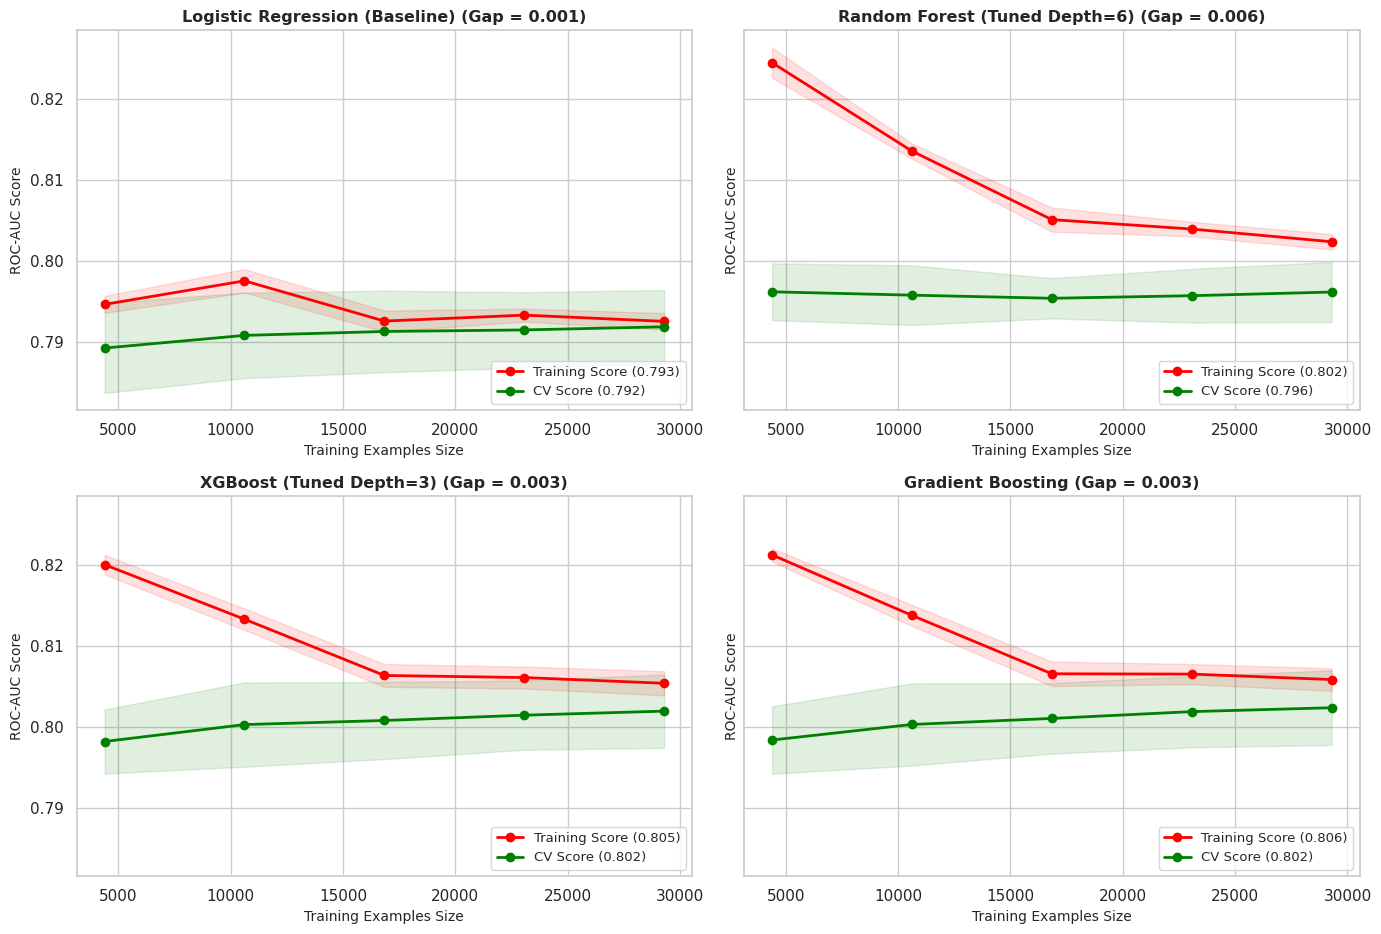

In [7]:
# Chọn 4 mô hình đại diện (trong đó có 3 Baseline Models đã cam kết trong Báo cáo)
models_to_plot = {
    "Logistic Regression (Baseline)": models["1. Logistic Regression (Baseline)"],
    "Random Forest (Tuned Depth=6)":  models["2. Random Forest"],
    "XGBoost (Tuned Depth=3)":        models["5. XGBoost"],
    "Gradient Boosting":              models["4. Gradient Boosting"]
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9.5), sharey=True)
axes = axes.ravel()
train_sizes = np.linspace(0.15, 1.0, 5)

for idx, (name, clf) in enumerate(models_to_plot.items()):
    ax = axes[idx]
    # Bọc ImbPipeline để nhất quán quy trình huấn luyện với SMOTETomek
    pipe_lc = ImbPipeline([
        ('Resampler', SMOTETomek(random_state=42)),
        ('Classifier', clf)
    ])
    train_sizes_out, train_scores, val_scores = learning_curve(
        pipe_lc, X_train, y_train, cv=cv, scoring='roc_auc',
        train_sizes=train_sizes, n_jobs=-1, random_state=42
    )

    train_mean, train_std = np.mean(train_scores, axis=1), np.std(train_scores, axis=1)
    val_mean, val_std = np.mean(val_scores, axis=1), np.std(val_scores, axis=1)

    ax.plot(train_sizes_out, train_mean, 'o-', color="r", lw=2, label=f"Training Score ({train_mean[-1]:.3f})")
    ax.plot(train_sizes_out, val_mean, 'o-', color="g", lw=2, label=f"CV Score ({val_mean[-1]:.3f})")
    ax.fill_between(train_sizes_out, train_mean - train_std, train_mean + train_std, alpha=0.12, color="r")
    ax.fill_between(train_sizes_out, val_mean - val_std, val_mean + val_std, alpha=0.12, color="g")

    gap = train_mean[-1] - val_mean[-1]
    ax.set_title(f"{name} (Gap = {gap:.3f})", fontsize=11.5, fontweight='bold')
    ax.set_xlabel("Training Examples Size", fontsize=10)
    ax.set_ylabel("ROC-AUC Score", fontsize=10)
    ax.legend(loc="lower right", fontsize=9.5)

plt.tight_layout()
plt.show()

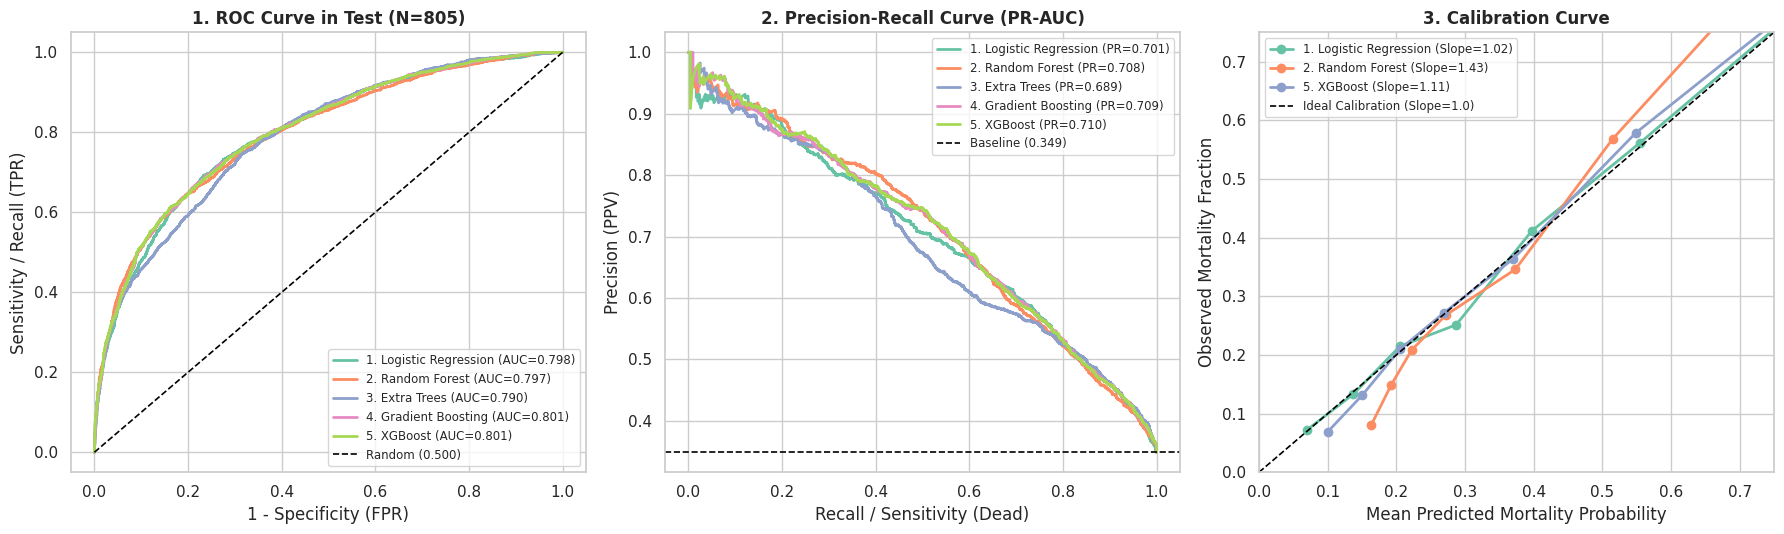


=== 4. MA TRẬN ĐÁNH GIÁ MÔ HÌNH TOÀN DIỆN TRÊN TẬP TEST  ===


,Mô hình,Ngưỡng J*,Test ROC-AUC,Test PR-AUC,Recall (Dead),Specificity (Alive),F1-Score,Brier Score (↓),Calib Slope (≈1.0),CITL (≈0.0)
0,5. XGBoost,0.485,0.8015,0.7103,66.8%,78.1%,0.6436,0.1645,1.111,-0.0010
1,4. Gradient Boosting,0.477,0.8014,0.7092,68.2%,77.0%,0.6457,0.1641,1.116,-0.0010
2,1. Logistic Regression (Baseline),0.519,0.7977,0.7015,68.6%,76.9%,0.6481,0.1675,1.021,-0.0004
3,2. Random Forest,0.474,0.7968,0.7085,68.8%,74.6%,0.6367,0.1695,1.428,-0.0013
4,3. Extra Trees,0.446,0.7902,0.6895,75.3%,67.5%,0.6384,0.1803,1.884,-0.0013


In [8]:
test_comparison = []
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for name, clf in models.items():
    # 1. Huấn luyện trên tập Train đã cân bằng SMOTETomek để tối ưu hóa phân loại (Discrimination & Recall)
    clf.fit(X_train_res, y_train_res)
    y_prob_test = clf.predict_proba(X_test)[:, 1]

    # Tìm ngưỡng tối ưu Youden's J trên tập Train (tránh chạm vào nhãn tập Test)
    y_prob_train = clf.predict_proba(X_train)[:, 1]
    fpr_tr, tpr_tr, thresholds_tr = roc_curve(y_train, y_prob_train)
    best_thresh = thresholds_tr[np.argmax(tpr_tr - fpr_tr)]

    y_pred_tuned = (y_prob_test >= best_thresh).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_tuned).ravel()

    auc_test  = roc_auc_score(y_test, y_prob_test)
    pr_auc    = average_precision_score(y_test, y_prob_test)
    rec_test  = recall_score(y_test, y_pred_tuned)
    spec_test = tn / (tn + fp)
    f1_test   = f1_score(y_test, y_pred_tuned)

    # 2. Đánh giá Calibration (Chuẩn PROBAST+AI Mục 5):
    # Huấn luyện bản hiệu chuẩn trên phân phối thực (X_train, y_train) để xác suất không bị đẩy vọt lên 50% do Oversampling
    clf_cal = LogisticRegression(C=1.0, max_iter=1000, random_state=42) if "Logistic" in name else clf.__class__(**clf.get_params())
    clf_cal.fit(X_train, y_train)
    y_prob_cal = np.clip(clf_cal.predict_proba(X_test)[:, 1], 1e-6, 1 - 1e-6)
    brier_cal  = brier_score_loss(y_test, y_prob_cal)

    # Tính Calibration Slope và Calibration-in-the-large (CITL)
    logit_p = logit(y_prob_cal).reshape(-1, 1)
    cal_lr = LogisticRegression(penalty=None, solver='lbfgs').fit(logit_p, y_test)
    cal_slope = cal_lr.coef_[0][0]
    citl = np.mean(y_test) - np.mean(y_prob_cal)

    test_comparison.append({
        'Mô hình': name,
        'Ngưỡng J*': round(best_thresh, 3),
        'Test ROC-AUC': round(auc_test, 4),
        'Test PR-AUC': round(pr_auc, 4),
        'Recall (Dead)': f"{rec_test*100:.1f}%",
        'Specificity (Alive)': f"{spec_test*100:.1f}%",
        'F1-Score': round(f1_test, 4),
        'Brier Score (↓)': round(brier_cal, 4),
        'Calib Slope (≈1.0)': round(cal_slope, 3),
        'CITL (≈0.0)': round(citl, 4)
    })

    # Vẽ ROC Curve
    fpr_te, tpr_te, _ = roc_curve(y_test, y_prob_test)
    axes[0].plot(fpr_te, tpr_te, lw=2, label=f"{name[:22]} (AUC={auc_test:.3f})")

    # Vẽ PR Curve
    prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_prob_test)
    axes[1].plot(rec_curve, prec_curve, lw=2, label=f"{name[:22]} (PR={pr_auc:.3f})")

    # Vẽ Calibration Curve cho 3 Baseline Models chính
    if any(k in name for k in ["Logistic", "Random Forest", "XGBoost"]):
        prob_true, prob_pred = calibration_curve(y_test, y_prob_cal, n_bins=7, strategy='quantile')
        axes[2].plot(prob_pred, prob_true, marker='o', lw=2, label=f"{name[:22]} (Slope={cal_slope:.2f})")

# Định dạng đồ thị 1: ROC Curve
axes[0].plot([0, 1], [0, 1], 'k--', lw=1.2, label='Random (0.500)')
axes[0].set_title('1. ROC Curve in Test (N=805)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('1 - Specificity (FPR)')
axes[0].set_ylabel('Sensitivity / Recall (TPR)')
axes[0].legend(loc='lower right', fontsize=8.5)

# Định dạng đồ thị 2: PR Curve
axes[1].axhline(y=y_test.mean(), color='k', linestyle='--', lw=1.2, label=f'Baseline ({y_test.mean():.3f})')
axes[1].set_title('2. Precision-Recall Curve (PR-AUC)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Recall / Sensitivity (Dead)')
axes[1].set_ylabel('Precision (PPV)')
axes[1].legend(loc='upper right', fontsize=8.5)

# Định dạng đồ thị 3: Calibration Curve
axes[2].plot([0, 0.75], [0, 0.75], 'k--', lw=1.2, label='Ideal Calibration (Slope=1.0)')
axes[2].set_title('3. Calibration Curve', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Mean Predicted Mortality Probability')
axes[2].set_ylabel('Observed Mortality Fraction')
axes[2].set_xlim([0, 0.75])
axes[2].set_ylim([0, 0.75])
axes[2].legend(loc='upper left', fontsize=8.5)

plt.tight_layout()
plt.show()

test_df = pd.DataFrame(test_comparison).sort_values(by='Test ROC-AUC', ascending=False).reset_index(drop=True)
print("\n=== 4. MA TRẬN ĐÁNH GIÁ MÔ HÌNH TOÀN DIỆN TRÊN TẬP TEST  ===")
display(test_df)